# Step 5. EDA & Visualization — Scheduled Departure Time Analysis

## Objective

This notebook explores how scheduled departure time is associated with arrival delays for flights departing from New York City airports in 2013.

We compare arrival delay patterns across four time periods and individual scheduled departure hours. We also examine moderate and severe delays to understand how delay patterns change throughout the day.

This analysis uses the cleaned dataset from Step 3 and builds on the descriptive statistics from Step 4. The findings are exploratory and do not establish causation.

## 1. Load & Validate Data

Load the cleaned flight dataset and check the scheduled departure hour and arrival delay variables for missing or invalid values.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")

data_path = Path("data/cleaned/analysis_ready_flights.csv")
fig_dir = Path("results/figures")
table_dir = Path("results/tables")

fig_dir.mkdir(parents=True, exist_ok=True)
table_dir.mkdir(parents=True, exist_ok=True)

analysis = pd.read_csv(data_path)

print("Dataset shape:", analysis.shape)
print("Missing scheduled hour:", analysis["scheduled_hour"].isna().sum())
print("Missing arrival delay:", analysis["arr_delay"].isna().sum())

invalid_hours = (
    analysis["scheduled_hour"].notna()
    & ~analysis["scheduled_hour"].between(0, 23)
)

print("Invalid scheduled hours:", invalid_hours.sum())

time_data = analysis.loc[
    analysis["scheduled_hour"].between(0, 23)
    & analysis["arr_delay"].notna()
].copy()

time_data["scheduled_hour"] = (
    time_data["scheduled_hour"].astype(int)
)

print("Valid observations:", f"{len(time_data):,}")
print("Excluded observations:", f"{len(analysis) - len(time_data):,}")

display(time_data[["scheduled_hour", "arr_delay"]].head())

Dataset shape: (327346, 34)
Missing scheduled hour: 0
Missing arrival delay: 0
Invalid scheduled hours: 0
Valid observations: 327,346
Excluded observations: 0


,scheduled_hour,arr_delay
0,5,11.0
1,5,20.0
2,5,33.0
3,5,-18.0
4,6,-25.0


## 2. Scheduled Departure Time Distribution

Group flights into four scheduled departure periods:

- Overnight: 00:00–05:59
- Morning: 06:00–11:59
- Afternoon: 12:00–17:59
- Evening: 18:00–23:59

Compare the number of flights across periods and individual hours.

In [2]:
time_order = [
    "Overnight",
    "Morning",
    "Afternoon",
    "Evening"
]

time_data["scheduled_time_period"] = pd.cut(
    time_data["scheduled_hour"],
    bins=[-1, 5, 11, 17, 23],
    labels=time_order
)

assert time_data["scheduled_time_period"].notna().all()

period_counts = (
    time_data["scheduled_time_period"]
    .value_counts()
    .reindex(time_order)
)

display(period_counts.to_frame("Flights"))

print("Total flights:", f"{period_counts.sum():,}")

,Flights
scheduled_time_period,
Overnight,1940
Morning,126646
Afternoon,127017
Evening,71743


Total flights: 327,346


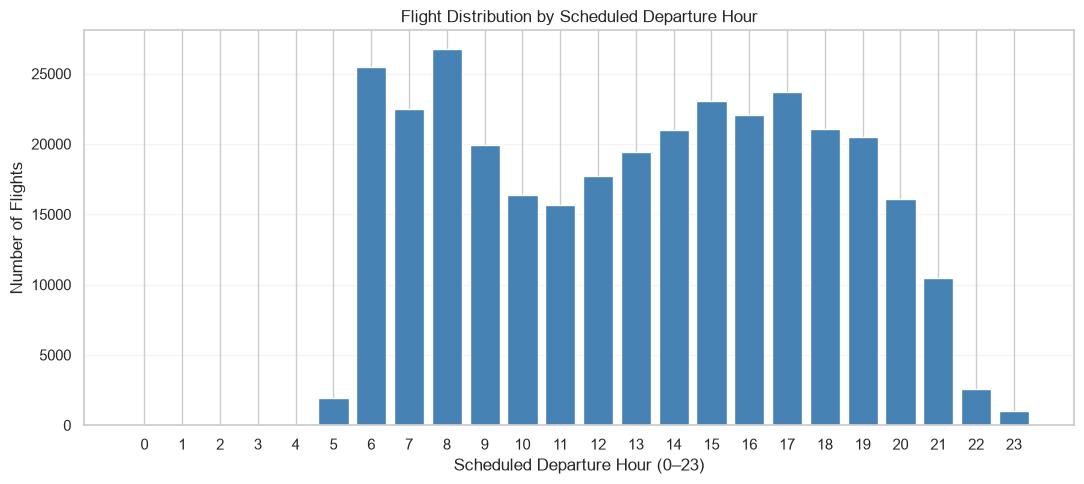

In [3]:
hourly_counts = (
    time_data.groupby("scheduled_hour")
    .size()
    .reindex(range(24), fill_value=0)
)

fig, ax = plt.subplots(figsize=(11, 5))

ax.bar(
    hourly_counts.index,
    hourly_counts.values,
    color="steelblue"
)

ax.set(
    title="Flight Distribution by Scheduled Departure Hour",
    xlabel="Scheduled Departure Hour (0–23)",
    ylabel="Number of Flights"
)

ax.set_xticks(range(24))
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    fig_dir / "scheduled_departure_hour_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 3. Arrival Delay Statistics by Time Period

Compare mean, median, standard deviation, and delay rates across the four scheduled departure periods.

Delay rates are calculated using thresholds of more than 15, 60, and 120 minutes.

In [4]:
time_stats = (
    time_data.groupby(
        "scheduled_time_period",
        observed=True
    )["arr_delay"]
    .agg(
        Flights="count",
        Mean="mean",
        Median="median",
        Std="std",
        Min="min",
        Max="max",
        Delay_Over_15_Pct=lambda x: (x > 15).mean() * 100,
        Delay_Over_60_Pct=lambda x: (x > 60).mean() * 100,
        Delay_Over_120_Pct=lambda x: (x > 120).mean() * 100
    )
    .reindex(time_order)
)

display(time_stats.round(2))

assert time_stats["Flights"].sum() == len(time_data)

print("Time period statistics calculated successfully!")

,Flights,Mean,Median,Std,Min,Max,Delay_Over_15_Pct,Delay_Over_60_Pct,Delay_Over_120_Pct
scheduled_time_period,,,,,,,,,
Overnight,1940,-4.80,-8.0,22.24,-51.0,208.0,9.95,1.60,0.46
Morning,126646,-1.78,-8.0,33.20,-79.0,1272.0,14.68,3.67,1.19
Afternoon,127017,10.43,-3.0,48.20,-86.0,1109.0,27.09,10.00,3.76
Evening,71743,16.27,0.0,52.64,-75.0,1127.0,34.06,14.50,5.21


Time period statistics calculated successfully!


### Mean vs. Median Arrival Delay by Time Period

Compare average and median arrival delays across time periods to understand typical delay patterns and the possible influence of large delays.

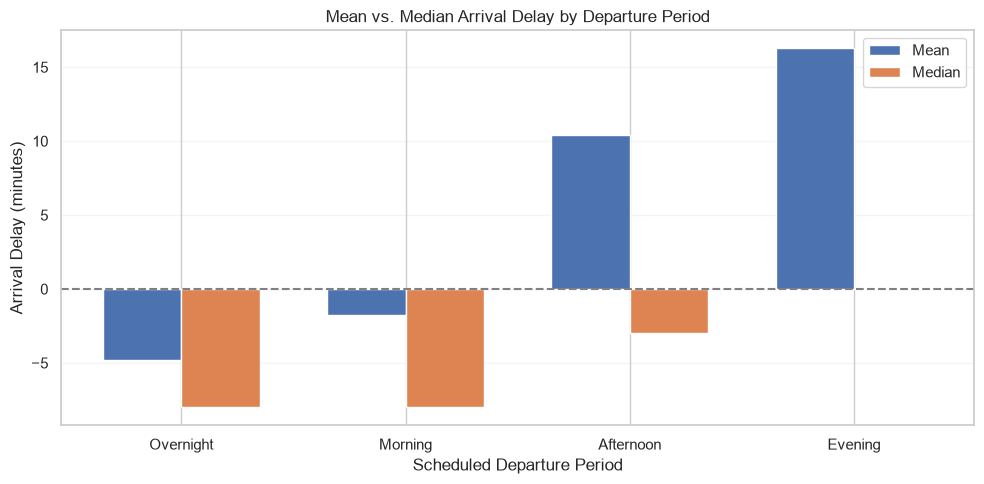

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(len(time_order))
width = 0.35

ax.bar(
    x - width / 2,
    time_stats["Mean"],
    width,
    label="Mean"
)

ax.bar(
    x + width / 2,
    time_stats["Median"],
    width,
    label="Median"
)

ax.set_xticks(x)
ax.set_xticklabels(time_order)

ax.axhline(0, color="gray", linestyle="--")

ax.set(
    title="Mean vs. Median Arrival Delay by Departure Period",
    xlabel="Scheduled Departure Period",
    ylabel="Arrival Delay (minutes)"
)

ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    fig_dir / "scheduled_departure_mean_vs_median.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 4. Arrival Delay by Scheduled Departure Hour

Analyze arrival delays for each scheduled departure hour from 0 to 23.

Hourly analysis provides a more detailed view of delay patterns that may be hidden when flights are grouped into broader time periods.

In [6]:
hourly_stats = (
    time_data.groupby("scheduled_hour")["arr_delay"]
    .agg(
        Flights="count",
        Mean="mean",
        Median="median",
        Std="std",
        Delay_Over_15_Pct=lambda x: (x > 15).mean() * 100,
        Delay_Over_60_Pct=lambda x: (x > 60).mean() * 100,
        Delay_Over_120_Pct=lambda x: (x > 120).mean() * 100
    )
    .reindex(range(24))
)

display(hourly_stats.round(2))

,Flights,Mean,Median,Std,Delay_Over_15_Pct,Delay_Over_60_Pct,Delay_Over_120_Pct
scheduled_hour,,,,,,,
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,1940.0,-4.80,-8.0,22.24,9.95,1.60,0.46
6,25447.0,-3.38,-8.0,28.26,11.29,2.39,0.83
7,22475.0,-5.30,-10.0,29.18,11.39,2.54,0.78
8,26734.0,-1.11,-8.0,33.81,15.72,3.94,1.21


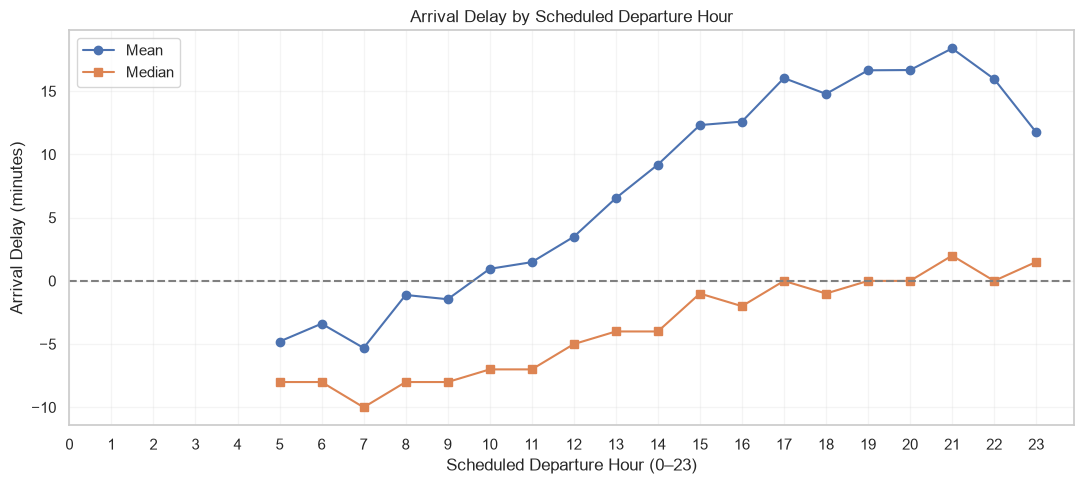

In [7]:
fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    hourly_stats.index,
    hourly_stats["Mean"],
    marker="o",
    label="Mean"
)

ax.plot(
    hourly_stats.index,
    hourly_stats["Median"],
    marker="s",
    label="Median"
)

ax.axhline(0, color="gray", linestyle="--")

ax.set(
    title="Arrival Delay by Scheduled Departure Hour",
    xlabel="Scheduled Departure Hour (0–23)",
    ylabel="Arrival Delay (minutes)"
)

ax.set_xticks(range(24))
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()

plt.savefig(
    fig_dir / "scheduled_departure_hourly_delay.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 5. Delay Rates by Time Period

Compare the percentages of flights delayed more than 15, 60, and 120 minutes.

These measures help identify which scheduled departure periods are associated with more frequent moderate and severe arrival delays.

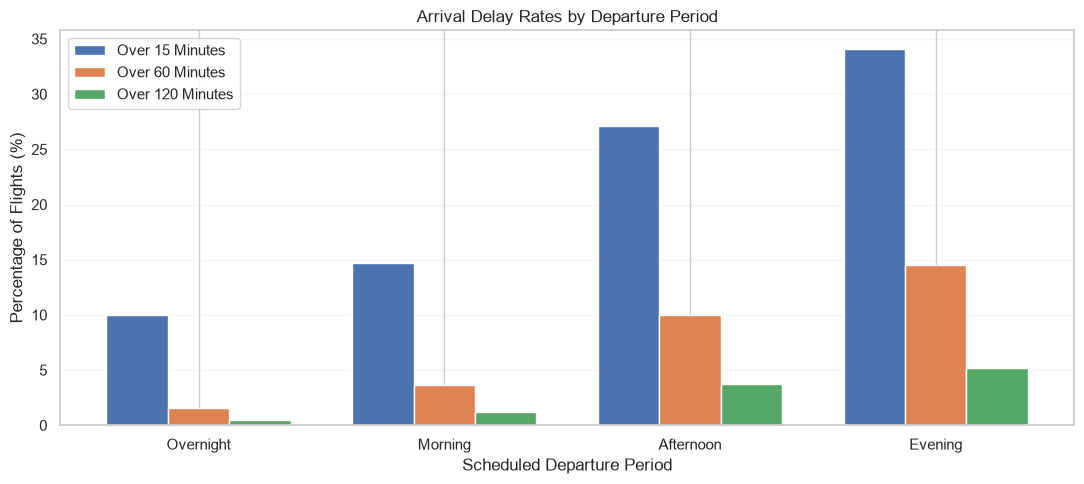

In [8]:
fig, ax = plt.subplots(figsize=(11, 5))

x = np.arange(len(time_order))
width = 0.25

ax.bar(
    x - width,
    time_stats["Delay_Over_15_Pct"],
    width,
    label="Over 15 Minutes"
)

ax.bar(
    x,
    time_stats["Delay_Over_60_Pct"],
    width,
    label="Over 60 Minutes"
)

ax.bar(
    x + width,
    time_stats["Delay_Over_120_Pct"],
    width,
    label="Over 120 Minutes"
)

ax.set_xticks(x)
ax.set_xticklabels(time_order)

ax.set(
    title="Arrival Delay Rates by Departure Period",
    xlabel="Scheduled Departure Period",
    ylabel="Percentage of Flights (%)"
)

ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    fig_dir / "scheduled_departure_delay_rates.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Hourly Delay Rates

Examine the percentage of flights delayed more than 15 and 60 minutes for each scheduled departure hour.

Hourly sample sizes should also be considered when interpreting the results.

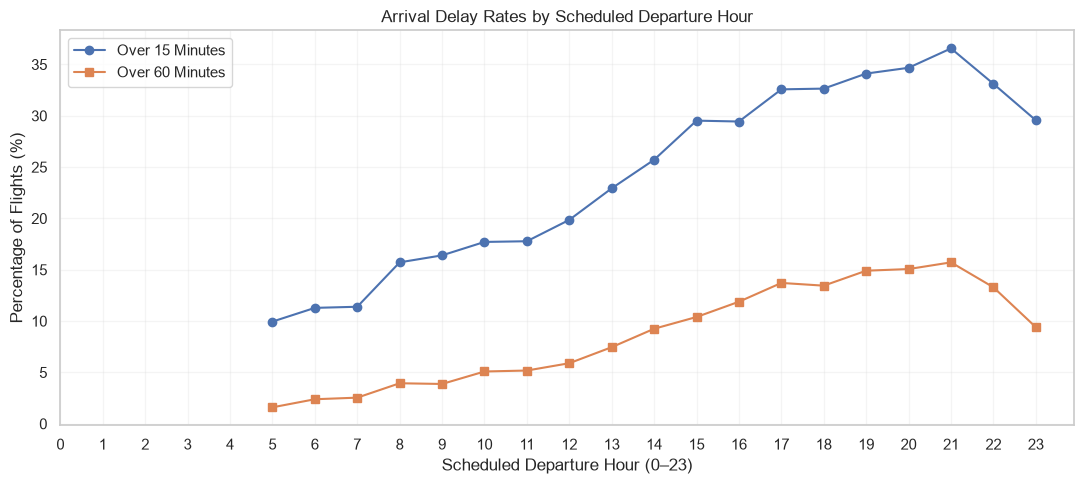

In [9]:
fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    hourly_stats.index,
    hourly_stats["Delay_Over_15_Pct"],
    marker="o",
    label="Over 15 Minutes"
)

ax.plot(
    hourly_stats.index,
    hourly_stats["Delay_Over_60_Pct"],
    marker="s",
    label="Over 60 Minutes"
)

ax.set(
    title="Arrival Delay Rates by Scheduled Departure Hour",
    xlabel="Scheduled Departure Hour (0–23)",
    ylabel="Percentage of Flights (%)"
)

ax.set_xticks(range(24))
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()

plt.savefig(
    fig_dir / "scheduled_departure_hourly_delay_rates.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 6. Arrival Delay Distribution by Time Period

Use a boxplot to compare the spread of arrival delays across scheduled departure periods.

The plot displays the full dataset's boxplot statistics, with the vertical axis limited to −60 to 180 minutes for readability. Extreme delays remain included in the statistical calculations.

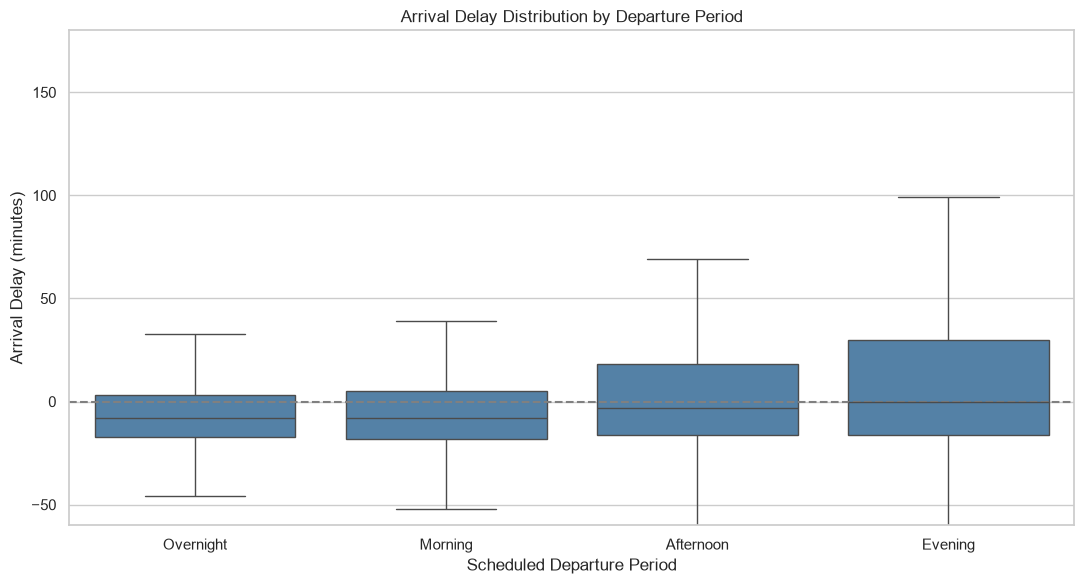

In [10]:
fig, ax = plt.subplots(figsize=(11, 6))

sns.boxplot(
    data=time_data,
    x="scheduled_time_period",
    y="arr_delay",
    order=time_order,
    showfliers=False,
    color="steelblue",
    ax=ax
)

ax.set_ylim(-60, 180)
ax.axhline(0, color="gray", linestyle="--")

ax.set(
    title="Arrival Delay Distribution by Departure Period",
    xlabel="Scheduled Departure Period",
    ylabel="Arrival Delay (minutes)"
)

plt.tight_layout()

plt.savefig(
    fig_dir / "scheduled_departure_delay_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 7. Extreme Delays and Sample Sizes

Examine flights delayed more than 120 minutes and compare sample sizes across departure periods.

This analysis helps identify periods with more severe delays while accounting for differences in the number of scheduled flights.

In [11]:
extreme_stats = (
    time_data.groupby(
        "scheduled_time_period",
        observed=True
    )["arr_delay"]
    .agg(
        Flights="count",
        Delays_Over_120=lambda x: (x > 120).sum(),
        Extreme_Delay_Pct=lambda x: (x > 120).mean() * 100,
        Maximum_Delay="max"
    )
    .reindex(time_order)
)

extreme_stats["Share_of_Total_Pct"] = (
    extreme_stats["Flights"] / len(time_data) * 100
)

display(extreme_stats.round(2))

,Flights,Delays_Over_120,Extreme_Delay_Pct,Maximum_Delay,Share_of_Total_Pct
scheduled_time_period,,,,,
Overnight,1940,9,0.46,208.0,0.59
Morning,126646,1511,1.19,1272.0,38.69
Afternoon,127017,4774,3.76,1109.0,38.80
Evening,71743,3740,5.21,1127.0,21.92


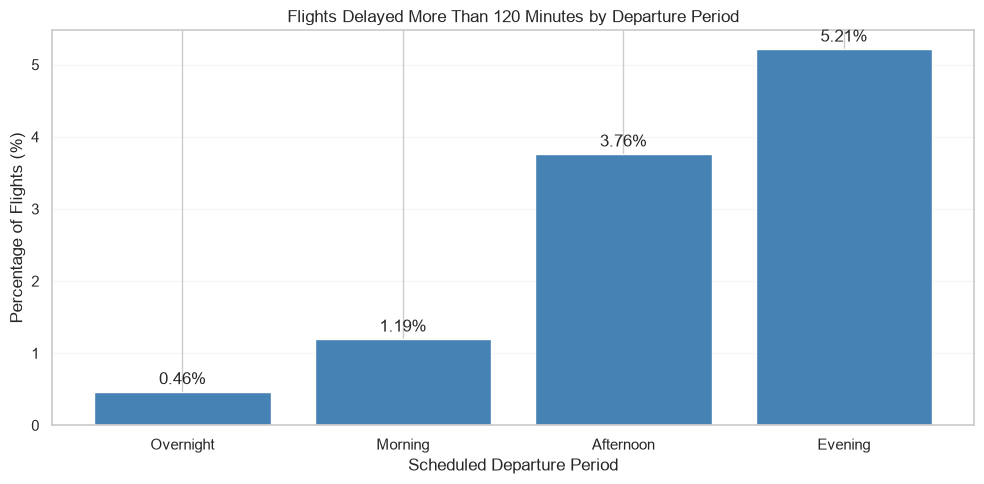

In [12]:
fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    extreme_stats.index,
    extreme_stats["Extreme_Delay_Pct"],
    color="steelblue"
)

ax.bar_label(bars, fmt="%.2f%%", padding=3)

ax.set(
    title="Flights Delayed More Than 120 Minutes by Departure Period",
    xlabel="Scheduled Departure Period",
    ylabel="Percentage of Flights (%)"
)

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    fig_dir / "scheduled_departure_extreme_delay_rates.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 8. Save Results

Export the descriptive statistics and visualizations for use in the project report and subsequent statistical analysis.

In [13]:
time_stats.round(2).to_csv(
    table_dir / "scheduled_departure_period_statistics.csv",
    index_label="scheduled_time_period"
)

hourly_stats.round(2).to_csv(
    table_dir / "scheduled_departure_hourly_statistics.csv",
    index_label="scheduled_hour"
)

extreme_stats.round(2).to_csv(
    table_dir / "scheduled_departure_extreme_delays.csv",
    index_label="scheduled_time_period"
)

print("All scheduled departure statistics saved successfully!")

All scheduled departure statistics saved successfully!


In [14]:
highest_mean = time_stats["Mean"].idxmax()
lowest_mean = time_stats["Mean"].idxmin()

highest_15 = time_stats["Delay_Over_15_Pct"].idxmax()
lowest_15 = time_stats["Delay_Over_15_Pct"].idxmin()

highest_60 = time_stats["Delay_Over_60_Pct"].idxmax()
highest_120 = time_stats["Delay_Over_120_Pct"].idxmax()

print(
    f"Overall mean arrival delay: "
    f"{time_data['arr_delay'].mean():.2f} minutes"
)

print(
    f"Overall median arrival delay: "
    f"{time_data['arr_delay'].median():.2f} minutes"
)

print(
    f"\nHighest mean delay: {highest_mean} "
    f"({time_stats.loc[highest_mean, 'Mean']:.2f} minutes)"
)

print(
    f"Lowest mean delay: {lowest_mean} "
    f"({time_stats.loc[lowest_mean, 'Mean']:.2f} minutes)"
)

print(
    f"\nHighest >15 min delay rate: {highest_15} "
    f"({time_stats.loc[highest_15, 'Delay_Over_15_Pct']:.2f}%)"
)

print(
    f"Lowest >15 min delay rate: {lowest_15} "
    f"({time_stats.loc[lowest_15, 'Delay_Over_15_Pct']:.2f}%)"
)

print(
    f"Highest >60 min delay rate: {highest_60} "
    f"({time_stats.loc[highest_60, 'Delay_Over_60_Pct']:.2f}%)"
)

print(
    f"Highest >120 min delay rate: {highest_120} "
    f"({time_stats.loc[highest_120, 'Delay_Over_120_Pct']:.2f}%)"
)

print("\nFlights by scheduled departure period:")
print(time_stats["Flights"].to_string())

# Hourly results with minimum sample-size requirement
eligible_hours = hourly_stats[
    hourly_stats["Flights"] >= 100
]

if not eligible_hours.empty:
    peak_hour = eligible_hours["Mean"].idxmax()

    print(
        f"\nHighest hourly mean delay (n >= 100): "
        f"{peak_hour:02d}:00 "
        f"({eligible_hours.loc[peak_hour, 'Mean']:.2f} minutes)"
    )

Overall mean arrival delay: 6.90 minutes
Overall median arrival delay: -5.00 minutes

Highest mean delay: Evening (16.27 minutes)
Lowest mean delay: Overnight (-4.80 minutes)

Highest >15 min delay rate: Evening (34.06%)
Lowest >15 min delay rate: Overnight (9.95%)
Highest >60 min delay rate: Evening (14.50%)
Highest >120 min delay rate: Evening (5.21%)

Flights by scheduled departure period:
scheduled_time_period
Overnight      1940
Morning      126646
Afternoon    127017
Evening       71743

Highest hourly mean delay (n >= 100): 21:00 (18.39 minutes)


## 9. Key Findings and Limitations

### Key Findings

The overall mean arrival delay was 6.90 minutes, while the median was −5 minutes, suggesting that some large delays increased the average.

Evening flights (18:00–23:59) had the highest mean arrival delay (16.27 minutes), while Overnight flights (00:00–05:59) had the lowest (−4.80 minutes).

Evening flights also had the highest percentage of flights delayed more than 15 minutes (34.06%), 60 minutes (14.50%), and 120 minutes (5.21%). In contrast, Overnight flights had the lowest percentage of flights delayed more than 15 minutes (9.95%).

Among scheduled departure hours with at least 100 flights, 21:00 had the highest mean arrival delay (18.39 minutes).

Overall, flights scheduled later in the day tended to experience greater arrival delays, especially during the Evening period. These findings suggest that scheduled departure time is associated with arrival delay patterns.

### Limitations

This analysis only includes flights departing from New York City airports in 2013, so the findings may not represent current flight operations.

The number of flights differs across departure periods. Overnight had only 1,940 flights, compared with 126,646 Morning flights, 127,017 Afternoon flights, and 71,743 Evening flights.

Other factors, such as airline, season, airport, flight distance, and weather conditions, may also be associated with arrival delays. These factors were not controlled for in this exploratory analysis.

Extreme delays may influence mean arrival delays. In addition, the results are descriptive and do not establish that scheduled departure time itself causes delays.

### Data Preparation and Quality Notes

This analysis uses the cleaned flight dataset prepared in Step 3, containing 327,346 flights.

The scheduled departure hour was derived from the scheduled departure time and represents the planned departure hour rather than the actual departure time.

Flights with missing arrival delay values were excluded during data cleaning.

Scheduled departure hours were grouped into four periods: Overnight (00:00–05:59), Morning (06:00–11:59), Afternoon (12:00–17:59), and Evening (18:00–23:59).

Both the hourly variable and the four time periods were used to examine arrival delay patterns.